# 01 · ETL: diagnóstico de calidad y limpieza

**Proyecto:** PyAppy ML Consultora · Sistema de recomendación para fidelizar clientes
**Responsable:** Alam Flores (Data Scientist) · Sprint 1

**Objetivo:** pasar del CSV crudo de Kaggle a un dataset limpio y documentado en `data/processed/`, sobre el que trabajan el EDA (`02_EDA`) y el modelado (`03_modelado`).

**Cómo está armado:**
1. Diagnóstico ligero de calidad: solo lo necesario para decidir la limpieza.
2. Limpieza paso a paso. Cada paso es una función de `src/limpieza.py` que registra su impacto en una bitácora.
3. Resumen del impacto, validaciones y guardado.

> Para reproducir: descargar el CSV de Kaggle en `data/raw/` y ejecutar el notebook de principio a fin.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Raíz del repo (el notebook vive en notebooks/)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import limpieza as lp

RUTA_CRUDA = RAIZ / "data/raw/Pakistan Largest Ecommerce Dataset.csv"
RUTA_SALIDA = RAIZ / "data/processed/transacciones_limpias.parquet"

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.figsize"] = (10, 4)

## 1. Diagnóstico de calidad

In [2]:
crudo = lp.cargar_crudo(RUTA_CRUDA)
print(f"Filas: {len(crudo):,} · Columnas: {crudo.shape[1]}")
crudo.head()

Filas: 1,048,575 · Columnas: 26


,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,sales_commission_code,discount_amount,payment_method,Working Date,BI Status,MV,Year,Month,Customer Since,M-Y,FY,Customer ID,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,211131.0,complete,7/1/2016,kreations_YI 06-L,1950.0,1.0,1950.0,100147443,Women's Fashion,\N,0.0,cod,7/1/2016,#REF!,"1,950",2016.0,7.0,2016-7,7-2016,FY17,1.0,NaN,NaN,NaN,NaN,NaN
1,211133.0,canceled,7/1/2016,kcc_Buy 2 Frey Air Freshener & Get 1 Kasual Body Spray Free,240.0,1.0,240.0,100147444,Beauty & Grooming,\N,0.0,cod,7/1/2016,Gross,240,2016.0,7.0,2016-7,7-2016,FY17,2.0,NaN,NaN,NaN,NaN,NaN
2,211134.0,canceled,7/1/2016,Ego_UP0017-999-MR0,2450.0,1.0,2450.0,100147445,Women's Fashion,\N,0.0,cod,7/1/2016,Gross,"2,450",2016.0,7.0,2016-7,7-2016,FY17,3.0,NaN,NaN,NaN,NaN,NaN
3,211135.0,complete,7/1/2016,kcc_krone deal,360.0,1.0,60.0,100147446,Beauty & Grooming,R-FSD-52352,300.0,cod,7/1/2016,Net,360,2016.0,7.0,2016-7,7-2016,FY17,4.0,NaN,NaN,NaN,NaN,NaN
4,211136.0,order_refunded,7/1/2016,BK7010400AG,555.0,2.0,1110.0,100147447,Soghaat,\N,0.0,cod,7/1/2016,Valid,"1,110",2016.0,7.0,2016-7,7-2016,FY17,5.0,NaN,NaN,NaN,NaN,NaN


In [3]:
# Tipos y porcentaje de nulos por columna, tal como vienen
resumen = pd.DataFrame({
    "tipo": crudo.dtypes.astype(str),
    "nulos": crudo.isna().sum(),
    "% nulos": (crudo.isna().mean() * 100).round(1),
})
resumen

,tipo,nulos,% nulos
item_id,float64,464051,44.3
status,str,464066,44.3
created_at,str,464051,44.3
sku,str,464071,44.3
price,float64,464051,44.3
qty_ordered,float64,464051,44.3
grand_total,float64,464051,44.3
increment_id,str,464051,44.3
category_name_1,str,464215,44.3
sales_commission_code,str,601229,57.3


Casi todas las columnas tienen exactamente la misma cantidad de nulos (~464 mil). Eso sugiere **filas completamente vacías** (relleno del export a Excel, que llega a 1.048.575 = 2²⁰ filas) y no faltantes reales. Lo comprobamos:

In [4]:
filas_vacias = crudo.isna().all(axis=1)
print(f"Filas 100 % vacías: {filas_vacias.sum():,} ({filas_vacias.mean():.1%})")
real = crudo[~filas_vacias]
print(f"Filas con datos: {len(real):,}")

# Nulos reales + marcador '\\N' (nulo exportado desde MySQL), que pandas no detecta solo
marcador = real.select_dtypes(include=["object", "string"]).apply(lambda s: s.str.strip().eq("\\N").sum())
faltantes = pd.DataFrame({"NaN": real.isna().sum(), "'\\N'": marcador}).fillna(0).astype(int)
faltantes = faltantes[faltantes.sum(axis=1) > 0]
faltantes["% total"] = (faltantes.sum(axis=1) / len(real) * 100).round(2)
faltantes.sort_values("% total", ascending=False)

Filas 100 % vacías: 464,051 (44.3%)
Filas con datos: 584,524


,NaN,'\N',% total
Unnamed: 21,584524,0,100.00
Unnamed: 22,584524,0,100.00
Unnamed: 23,584524,0,100.00
Unnamed: 24,584524,0,100.00
Unnamed: 25,584524,0,100.00
sales_commission_code,137178,339001,81.46
category_name_1,164,7850,1.37
Customer ID,11,0,0.00
Customer Since,11,0,0.00
sku,20,0,0.00


### Estados de la transacción

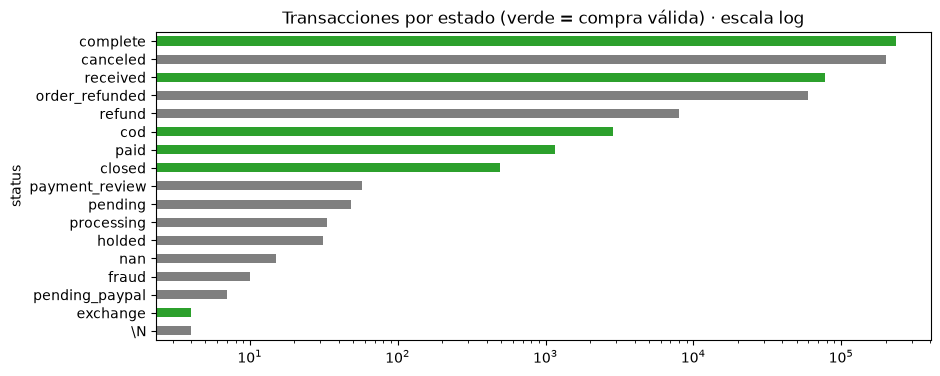

BI Status,#REF!,Gross,Net,Valid
status,,,,
NaN,0,15,0,0
\N,0,4,0,0
canceled,0,201249,0,0
closed,0,0,494,0
cod,0,0,0,2859
complete,1,0,233684,0
exchange,0,0,0,4
fraud,0,10,0,0
holded,0,31,0,0


In [5]:
estados = real["status"].value_counts(dropna=False)
ax = estados.plot.barh(color=["tab:green" if s in lp.ESTADOS_VALIDOS else "tab:gray" for s in estados.index])
ax.invert_yaxis(); ax.set_xscale("log")
ax.set_title("Transacciones por estado (verde = compra válida) · escala log")
plt.show()
pd.crosstab(real["status"].fillna("NaN"), real["BI Status"])

- `BI Status` es una función de `status`: Gross = cancelada o pendiente, Net = completada o cerrada, Valid = recibida, pagada o reembolsada. No aporta información nueva, así que la quitamos.
- **Definición de compra válida (decisión del equipo):** `complete`, `received`, `closed`, `paid`, `cod` y `exchange`. Se excluyen canceladas, reembolsos, fraude y pendientes. Un reembolso no es una preferencia que queramos recomendar.

### Columnas redundantes

In [6]:
r = real.copy()
fecha = pd.to_datetime(r["created_at"], format="%m/%d/%Y")
mv = pd.to_numeric(r[" MV "].str.replace(",", "").str.strip(), errors="coerce")
pruebas = {
    "Working Date == created_at": (r["Working Date"] == r["created_at"]).mean(),
    "Year == año(created_at)": (r["Year"] == fecha.dt.year).mean(),
    "Month == mes(created_at)": (r["Month"] == fecha.dt.month).mean(),
    "MV == price × qty": ((mv - r["price"] * r["qty_ordered"]).abs() < 1).mean(),
    "MV no numérico (' - ')": mv.isna().mean(),
}
pd.Series(pruebas, name="% de filas").map("{:.2%}".format)

Working Date == created_at    100.00%
Year == año(created_at)       100.00%
Month == mes(created_at)      100.00%
MV == price × qty              99.62%
MV no numérico (' - ')          0.38%
Name: % de filas, dtype: str

`Working Date`, `Year`, `Month`, `M-Y` y `FY` salen directo de la fecha. `MV` es el valor bruto (price × qty) guardado como texto con comas, y donde no coincide es porque price = 0 (vale `" - "`). Las quitamos todas.

### ¿`grand_total` es por línea o por pedido?

In [7]:
r["linea"] = r["price"] * r["qty_ordered"] - r["discount_amount"]
por_pedido = r.groupby("increment_id").agg(total=("grand_total", "first"),
                                          totales_distintos=("grand_total", "nunique"),
                                          suma_lineas=("linea", "sum"),
                                          items=("item_id", "size"))
multi = por_pedido[por_pedido["items"] > 1]
print(f"Pedidos con más de un ítem: {len(multi):,}")
print(f"grand_total constante dentro del pedido: {(multi['totales_distintos'] == 1).mean():.1%}")
print(f"grand_total == suma de líneas: {((multi['total'] - multi['suma_lineas']).abs() < 1).mean():.1%}")

Pedidos con más de un ítem: 81,854
grand_total constante dentro del pedido: 100.0%
grand_total == suma de líneas: 78.7%


`grand_total` es **el total del pedido**, repetido en cada línea. Sumarlo por ítem inflaría el ticket. El ticket promedio (KPI) se calcula por pedido tomando `grand_total` una vez por `increment_id`.

Además, solo el ~79 % de los pedidos cuadra con la suma de líneas, porque el `discount_amount` tampoco es confiable a nivel línea:

In [8]:
bruto = r["price"] * r["qty_ordered"]
desc_mayor = r["discount_amount"] > bruto
print(f"Líneas con descuento > price × qty: {desc_mayor.sum():,}")
desc_ped = r.assign(bruto=bruto).groupby("increment_id")[["bruto", "discount_amount"]].sum()
print(f"Pedidos cuyo descuento total supera su valor bruto: {(desc_ped['discount_amount'] > desc_ped['bruto'] + 1).sum():,}")
r.loc[desc_mayor, ["increment_id", "price", "qty_ordered", "discount_amount", "grand_total"]].head()

Líneas con descuento > price × qty: 9,713
Pedidos cuyo descuento total supera su valor bruto: 1,126


,increment_id,price,qty_ordered,discount_amount,grand_total
155307,100271403,110.0,1.0,200.3750,604.25
155511,100271572,269.0,1.0,381.3000,4321.40
155648,100271675,100.0,1.0,138.2367,683.29
158368,100273658,55.0,2.0,203.3000,637.40
159975,100274724,10.0,1.0,133.5833,604.25


El descuento de un pedido se reparte de forma irregular entre sus líneas. Por eso creamos dos montos por ítem:
- `monto_bruto = price × qty`: siempre ≥ 0 y confiable (coincide con `MV`). **Es el recomendado para medir el volumen de compra.**
- `monto_linea = max(price × qty − descuento, 0)`: el monto neto, recortado a 0 y con la bandera `descuento_inconsistente` en las líneas afectadas.

### Duplicados

In [9]:
cols_sin_id = [c for c in r.columns if c not in ("item_id", "linea")]
print(f"Duplicados exactos: {real.duplicated().sum():,}")
print(f"item_id repetidos: {real['item_id'].duplicated().sum():,}")
casi = r.duplicated(cols_sin_id, keep=False)
print(f"Filas idénticas salvo item_id: {r.duplicated(cols_sin_id).sum():,}")

# ¿Son errores o compras reales? Si el grand_total del pedido las incluye, son reales.
pedidos = r.loc[casi, "increment_id"].unique()
sub = r[r["increment_id"].isin(pedidos)]
con = sub.groupby("increment_id").agg(total=("grand_total", "first"), suma=("linea", "sum"))
sin = sub.drop_duplicates(cols_sin_id).groupby("increment_id")["linea"].sum()
print(f"grand_total cuadra CONTANDO las repetidas: {((con['total'] - con['suma']).abs() < 1).mean():.1%}")
print(f"grand_total cuadra SIN las repetidas:      {((con['total'] - sin).abs() < 1).mean():.1%}")

Duplicados exactos: 0
item_id repetidos: 0


Filas idénticas salvo item_id: 194
grand_total cuadra CONTANDO las repetidas: 89.0%
grand_total cuadra SIN las repetidas:      0.6%


No hay duplicados exactos. Las 194 líneas repetidas (mismo pedido, sku y monto, distinto `item_id`) **se conservan**: el total del pedido las incluye, así que corresponden al mismo producto agregado dos veces al carrito.

### Valores inválidos o atípicos

In [10]:
pd.Series({
    "price = 0": (real["price"] == 0).sum(),
    "grand_total < 0": (real["grand_total"] < 0).sum(),
    "discount_amount < 0": (real["discount_amount"] < 0).sum(),
    f"qty_ordered > {lp.UMBRAL_QTY_ATIPICA}": (real["qty_ordered"] > lp.UMBRAL_QTY_ATIPICA).sum(),
}, name="filas")

price = 0              2232
grand_total < 0          76
discount_amount < 0       3
qty_ordered > 100        42
Name: filas, dtype: int64

Período: 2016-07-01 a 2018-08-28


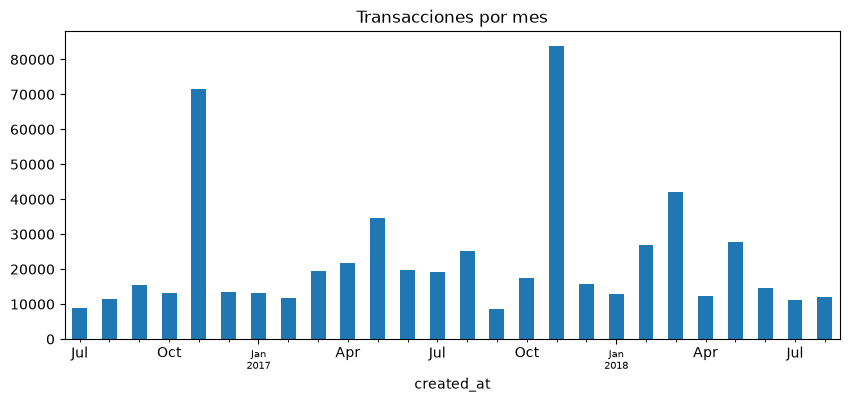

In [11]:
fechas = pd.to_datetime(real["created_at"], format="%m/%d/%Y")
print(f"Período: {fechas.min():%Y-%m-%d} a {fechas.max():%Y-%m-%d}")
fechas.dt.to_period("M").value_counts().sort_index().plot.bar(title="Transacciones por mes", color="tab:blue")
plt.xticks(fontsize=7); plt.show()

Los datos van de **julio de 2016 a agosto de 2018**, no desde marzo de 2016 como decía la propuesta. Hay picos fuertes en noviembre de 2016 y de 2017 (11.11 / Black Friday): hay que tenerlos en cuenta en el split temporal y en el EDA.

## 2. Limpieza paso a paso

Cada función de `src/limpieza.py` registra en `log` las filas antes y después y los valores afectados.

In [12]:
del real, r, sub  # liberar memoria del diagnóstico
log = []
df = crudo.copy()
lp.registrar_paso(log, "Carga", len(df), len(df), 0, "CSV crudo de Kaggle.")

**2.1 Filas y columnas vacías:** relleno del export, sin información.

In [13]:
df = lp.eliminar_filas_y_columnas_vacias(df, log)
df.shape

(584524, 21)

**2.2 Nombres y texto:** snake_case (` MV ` tenía espacios), strip, `\N` → NaN, `payment_method` en minúsculas.

In [14]:
df = lp.normalizar_nombres(df, log)
df = lp.normalizar_texto(df, log)
list(df.columns)

['item_id',
 'status',
 'created_at',
 'sku',
 'price',
 'qty_ordered',
 'grand_total',
 'increment_id',
 'category_name_1',
 'sales_commission_code',
 'discount_amount',
 'payment_method',
 'working_date',
 'bi_status',
 'mv',
 'year',
 'month',
 'customer_since',
 'm_y',
 'fy',
 'customer_id']

**2.3 Tipos:** fechas a `datetime` e identificadores a entero.

In [15]:
df = lp.convertir_tipos(df, log)
df.dtypes

item_id                           Int64
status                              str
created_at               datetime64[us]
sku                                 str
price                           float64
qty_ordered                       Int64
grand_total                     float64
increment_id                        str
category_name_1                     str
sales_commission_code               str
discount_amount                 float64
payment_method                      str
working_date                        str
bi_status                           str
mv                                  str
year                            float64
month                           float64
customer_since           datetime64[us]
m_y                                 str
fy                                  str
customer_id                       Int64
dtype: object

**2.4 Redundantes:** se quitan las columnas probadas en el diagnóstico. `sales_commission_code` (81 % faltante) pasa a ser la bandera `uso_codigo_comision`.

In [16]:
df = lp.eliminar_redundantes(df, log)

**2.5 Nulos:**
- Se eliminan las filas sin `customer_id`, `status` o `sku` (son unas decenas): sin ese dato no se puede atribuir la compra a un cliente ni a un producto.
- Categoría faltante: se imputa con la categoría más frecuente del mismo `sku`. Si el sku nunca aparece con categoría, queda `"Desconocida"` y no se borra la fila, porque la compra sigue siendo útil para el recomendador.

In [17]:
df = lp.tratar_nulos(df, log)
df["category_name_1"].value_counts()

category_name_1
Mobiles & Tablets     115865
Men's Fashion          92299
Women's Fashion        59725
Appliances             52457
Superstore             44015
Beauty & Grooming      41493
Soghaat                34011
Others                 30652
Home & Living          26504
Entertainment          26322
Health & Sports        17502
Kids & Baby            16489
Computing              15933
Desconocida             5859
School & Education      3478
Books                   1870
Name: count, dtype: int64

**2.6 Duplicados:** se eliminan los exactos o con `item_id` repetido (ninguno) y se conservan las líneas repetidas legítimas.

In [18]:
df = lp.tratar_duplicados(df, log)

**2.7 Productos de prueba:** el catálogo incluye SKUs de prueba internos de la tienda (`test-product`, `test bundle product`, `Test Hazir Product`, `test_tcsconnect`…), con precios simbólicos (mediana 5 PKR). No son ventas reales, y un recomendador por popularidad podría llegar a recomendarlos, así que **se eliminan**.

El patrón (`lp.PATRON_PRODUCTO_PRUEBA`) deja afuera a propósito los productos reales que contienen "test":

In [19]:
es_prueba = df["sku"].str.contains(lp.PATRON_PRODUCTO_PRUEBA, regex=True)
contiene_test = df["sku"].str.contains("test", case=False)
print(f"Filas de prueba: {es_prueba.sum():,} · SKUs: {df.loc[es_prueba, 'sku'].nunique()} · "
      f"marcadas como válidas por estado: {(es_prueba & df['status'].isin(lp.ESTADOS_VALIDOS)).sum()}")
print("\nSKUs de prueba más frecuentes:")
print(df.loc[es_prueba, "sku"].value_counts().head(8).to_string())
print("\nContienen 'test' pero son productos reales (se conservan):")
print(df.loc[contiene_test & ~es_prueba, "sku"].value_counts().to_string())

Filas de prueba: 1,773 · SKUs: 25 · marcadas como válidas por estado: 83

SKUs de prueba más frecuentes:
sku
test-product-00                             774
test-product                                611
test-product-3                              182
test_tcsconnect                              71
test-product-01                              37
test-product-new                             27
AhadTest Cnfg pricechange Discounted-MED     13
test bundle product-test-product-01           6

Contienen 'test' pero son productos reales (se conservan):
sku
SKMT_Blood Test                                 8
Aladdin_Test Star Cricket Ball - Red & White    3
sst_Vous Deteste-Regular fit-Medium             2


Algunas cuentas mezclan muchas compras de prueba con compras normales: probablemente son del personal de la tienda. No se borran. Se marcan con `cuenta_interna_probable` si al menos el 30 % de sus compras eran de prueba, y el EDA decide si las excluye (por ejemplo, de los clientes "top").

In [20]:
df = lp.tratar_productos_prueba(df, log)
df.loc[df["cuenta_interna_probable"]].groupby("customer_id").size().sort_values(ascending=False).head()

customer_id
1423     281
73       198
83       140
54        88
37733     51
dtype: int64

**2.8 Inválidos:** se corrigen o se marcan, sin borrar.
- Descuento negativo → 0.
- Descuento mayor que price × qty → bandera `descuento_inconsistente`.
- `grand_total` < 0, price = 0 y qty > 100 se marcan con una bandera. El EDA decide qué hacer con las compras mayoristas.

In [21]:
df = lp.tratar_invalidos(df, log)

**2.9 Variables nuevas y bandera de compra válida.**

In [22]:
df = lp.crear_variables(df, log)
df = lp.marcar_compra_valida(df, log)
df = df[lp.ORDEN_COLUMNAS]
df.head()

,item_id,increment_id,customer_id,customer_since,created_at,anio_mes,status,es_compra_valida,sku,category_name_1,price,qty_ordered,discount_amount,monto_bruto,monto_linea,grand_total,payment_method,uso_codigo_comision,precio_cero,descuento_inconsistente,grand_total_negativo,qty_atipica,cuenta_interna_probable
0,211131,100147443,1,2016-07-01,2016-07-01,2016-07,complete,True,kreations_YI 06-L,Women's Fashion,1950.0,1,0.0,1950.0,1950.0,1950.0,cod,False,False,False,False,False,False
1,211133,100147444,2,2016-07-01,2016-07-01,2016-07,canceled,False,kcc_Buy 2 Frey Air Freshener & Get 1 Kasual Body Spray Free,Beauty & Grooming,240.0,1,0.0,240.0,240.0,240.0,cod,False,False,False,False,False,False
2,211134,100147445,3,2016-07-01,2016-07-01,2016-07,canceled,False,Ego_UP0017-999-MR0,Women's Fashion,2450.0,1,0.0,2450.0,2450.0,2450.0,cod,False,False,False,False,False,False
3,211135,100147446,4,2016-07-01,2016-07-01,2016-07,complete,True,kcc_krone deal,Beauty & Grooming,360.0,1,300.0,360.0,60.0,60.0,cod,True,False,False,False,False,False
4,211136,100147447,5,2016-07-01,2016-07-01,2016-07,order_refunded,False,BK7010400AG,Soghaat,555.0,2,0.0,1110.0,1110.0,1110.0,cod,False,False,False,False,False,False


## 3. Resumen del impacto

In [23]:
bitacora = lp.bitacora_a_df(log)
bitacora

,paso,filas_antes,filas_despues,filas_eliminadas,valores_afectados,motivo
0,Carga,1048575,1048575,0,0,CSV crudo de Kaggle.
1,Filas vacías,1048575,584524,464051,464051,Filas sin ningún dato: relleno del export a Excel.
2,Columnas vacías,584524,584524,0,5,"Columnas 100 % vacías: Unnamed: 21, Unnamed: 22, Unnamed: 23, Unnamed: 24, Unnamed: 25."
3,Nombres de columnas,584524,584524,0,21,Nombres en snake_case para evitar errores por espacios.
4,Texto y marcador \N,584524,584524,0,346855,'\N' es el nulo de MySQL: se trata como faltante. Strip de espacios.
5,Tipos de datos,584524,584524,0,5,"created_at y customer_since a fecha; item_id, customer_id y qty_ordered a entero."
6,Columnas redundantes,584524,584524,0,8,working_date = created_at; year/month/m_y/fy salen de la fecha; mv = price×qty; bi_status depende solo de status. sa...
7,Nulos en columnas clave,584524,584474,50,50,"Sin customer_id, status o sku la transacción no se puede atribuir."
8,Categoría por sku,584474,584474,0,2134,Categoría faltante imputada con la categoría más frecuente del mismo sku.
9,Categoría desconocida,584474,584474,0,5859,Sin referencia en otro registro del sku → 'Desconocida'.


In [24]:
inicial, final = bitacora["filas_antes"].iloc[0], len(df)
vacias = bitacora.loc[bitacora["paso"] == "Filas vacías", "filas_eliminadas"].item()
print(f"Filas crudas: {inicial:,}")
print(f"  − vacías (relleno):            {vacias:,}")
print(f"  − otras eliminadas:            {inicial - vacias - final:,}  ({(inicial - vacias - final) / (inicial - vacias):.3%} de las reales)")
print(f"Filas finales: {final:,}")
validas = df[df["es_compra_valida"]]
print(f"Compras válidas: {len(validas):,} ({len(validas) / final:.1%})")
print(f"Clientes con compra válida: {validas['customer_id'].nunique():,} · SKUs: {validas['sku'].nunique():,}")

Filas crudas: 1,048,575
  − vacías (relleno):            464,051
  − otras eliminadas:            1,823  (0.312% de las reales)
Filas finales: 582,701
Compras válidas: 314,565 (54.0%)
Clientes con compra válida: 79,946 · SKUs: 63,970


**Lectura:** salvo las filas vacías del export, la limpieza elimina solo un ~0,3 % de los registros reales: transacciones sin clave y productos de prueba. Las demás decisiones corrigen o marcan valores. Así el EDA conserva toda la información (cancelaciones incluidas) y el modelado filtra con `es_compra_valida`.

## 4. Validaciones

In [25]:
claves = ["customer_id", "sku", "status", "created_at", "category_name_1", "item_id"]
assert df[claves].notna().all().all(), "Hay nulos en columnas clave"
assert df["item_id"].is_unique, "item_id no es único"
assert (df["discount_amount"] >= 0).all(), "Descuentos negativos"
assert bitacora["filas_eliminadas"].sum() == inicial - final, "La bitácora no cuadra con las filas"
assert not df.loc[df["es_compra_valida"], "precio_cero"].any()
assert (df["monto_linea"] >= 0).all() and (df["monto_linea"] <= df["monto_bruto"]).all(), "monto_linea fuera de rango"
assert (df.groupby("increment_id")["customer_id"].nunique() == 1).all(), "Pedido con más de un cliente"
assert (df.groupby("increment_id")["grand_total"].nunique() == 1).all(), "grand_total no constante en el pedido"
assert df["created_at"].between("2016-07-01", "2018-08-31").all(), "Fechas fuera de rango"
assert not df["sku"].str.contains(lp.PATRON_PRODUCTO_PRUEBA, regex=True).any(), "Quedan productos de prueba"
print("✓ Todas las validaciones pasaron")

✓ Todas las validaciones pasaron


## 5. Guardado

In [26]:
RUTA_SALIDA.parent.mkdir(parents=True, exist_ok=True)
df.to_parquet(RUTA_SALIDA, index=False)

releido = pd.read_parquet(RUTA_SALIDA)
assert releido.shape == df.shape and (releido.dtypes == df.dtypes).all()
print(f"Guardado: {RUTA_SALIDA.relative_to(RAIZ)} · {RUTA_SALIDA.stat().st_size / 1e6:.1f} MB · {releido.shape}")

# Bitácora exportada para la documentación del sprint
(RAIZ / "docs/bitacora_etl.md").write_text(
    "# Bitácora del ETL\n\nGenerada automáticamente por `notebooks/01_ETL.ipynb`.\n\n"
    + lp.bitacora_a_markdown(log) + "\n", encoding="utf-8")

Guardado: data/processed/transacciones_limpias.parquet · 16.3 MB · (582701, 23)


2992

## 6. Notas para el EDA y el modelado
- **Filtrar compras:** `df[df.es_compra_valida]`.
- **Ticket promedio:** calcular por pedido, con `grand_total` una vez por `increment_id`. Si se suma por ítem, el ticket se infla.
- **Cold start / sparsity:** la mayoría de los clientes tiene una sola compra válida y hay decenas de miles de SKUs. Conviene que el EDA lo cuantifique y evalúe agrupar a nivel `category_name_1`.
- **Pedidos que perdieron líneas:** 55 pedidos perdieron alguna línea en la limpieza (productos de prueba o filas sin clave), así que su `grand_total` todavía las incluye. Solo 14 tienen compras válidas: el efecto en el ticket es despreciable.
- **Estacionalidad:** los picos de noviembre afectan el split temporal.
- **Montos:** usar `monto_bruto` para el volumen de compra. `monto_linea` y `discount_amount` son poco confiables donde `descuento_inconsistente` es True.
- **Revisar en el EDA:** compras con `qty_atipica`, categoría `"Desconocida"` y clientes con `cuenta_interna_probable`.
- **Casos menores que se conservan:** 9 líneas con `increment_id` terminado en `-1` (pedidos re-emitidos; el pedido base también existe) y 2 SKUs `ajrak` cargados en Women's y Men's Fashion.